In [1]:

import pandas as pd
from pathlib import Path

# Locate the dataset
file_path = Path("../data/raw/1.csv")

# Load the dataset
df = pd.read_csv(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Number of rows and columns: (1063, 1)

Column names:
['datetime;Accelerometer1RMS;Accelerometer2RMS;Current;Pressure;Temperature;Thermocouple;Voltage;Volume Flow RateRMS;anomaly;changepoint']

First 5 rows:
  datetime;Accelerometer1RMS;Accelerometer2RMS;Current;Pressure;Temperature;Thermocouple;Voltage;Volume Flow RateRMS;anomaly;changepoint
0  2020-03-09 16:16:30;0.0275454;0.0411269;0.6735...                                                                                    
1  2020-03-09 16:16:31;0.027996899999999998;0.039...                                                                                    
2  2020-03-09 16:16:32;0.028418400000000003;0.038...                                                                                    
3  2020-03-09 16:16:33;0.0276254;0.0393665;0.5662...                                                                                    
4  2020-03-09 16:16:34;0.0274841;0.0418539;1.2921...                           

In [2]:

import pandas as pd
from pathlib import Path

# Correctly load the semicolon-separated dataset
file_path = Path("../data/raw/1.csv")
df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Rows and columns: (1063, 11)

Column names:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:
              datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
0  2020-03-09 16:16:30           0.027545           0.041127  0.673506   
1  2020-03-09 16:16:31           0.027997           0.039100  0.772264   
2  2020-03-09 16:16:32           0.028418           0.038872  0.675520   
3  2020-03-09 16:16:33           0.027625           0.039366  0.566279   
4  2020-03-09 16:16:34           0.027484           0.041854  1.292170   

   Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  \
0  0.054711      67.8345       24.3164  240.513                 32.0      0.0   
1  0.054711      67.8704       24.3279  229.523                 32.0      0.0   
2  0.054711      67.7882       24.3261  242.708        

In [3]:

# Convert datetime text to datetime objects
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Check data types
print("Updated data types:")
print(df.dtypes)

# Check invalid datetime values
print("\nInvalid datetime values:")
print(df["datetime"].isna().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check dataset size
print("\nDataset shape:")
print(df.shape)


Updated data types:
datetime               datetime64[us]
Accelerometer1RMS             float64
Accelerometer2RMS             float64
Current                       float64
Pressure                      float64
Temperature                   float64
Thermocouple                  float64
Voltage                       float64
Volume Flow RateRMS           float64
anomaly                       float64
changepoint                   float64
dtype: object

Invalid datetime values:
0

Duplicate rows:
0

Dataset shape:
(1063, 11)


In [4]:

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Statistical summary
print(numeric_df.describe().T)

# Check for infinite values
import numpy as np

print("\nInfinite values per column:")
print(np.isinf(numeric_df).sum())


                      count        mean        std        min         25%  \
Accelerometer1RMS    1063.0    0.027663   0.000333   0.026455    0.027434   
Accelerometer2RMS    1063.0    0.040037   0.001086   0.036972    0.039276   
Current              1063.0    1.195240   7.113407   0.394058    0.753505   
Pressure             1063.0    0.048541   0.270689  -0.929070    0.054711   
Temperature          1063.0   67.895174   0.695198  66.201900   67.412450   
Thermocouple         1063.0   24.265096   0.021573  24.217000   24.252950   
Voltage              1063.0  229.924824  13.259556   0.580776  223.570000   
Volume Flow RateRMS  1063.0   31.472275   1.314535  28.040000   31.039050   
anomaly              1063.0    0.313264   0.464039   0.000000    0.000000   
changepoint          1063.0    0.003763   0.061256   0.000000    0.000000   

                            50%         75%         max  
Accelerometer1RMS      0.027674    0.027892    0.028554  
Accelerometer2RMS      0.040098    0

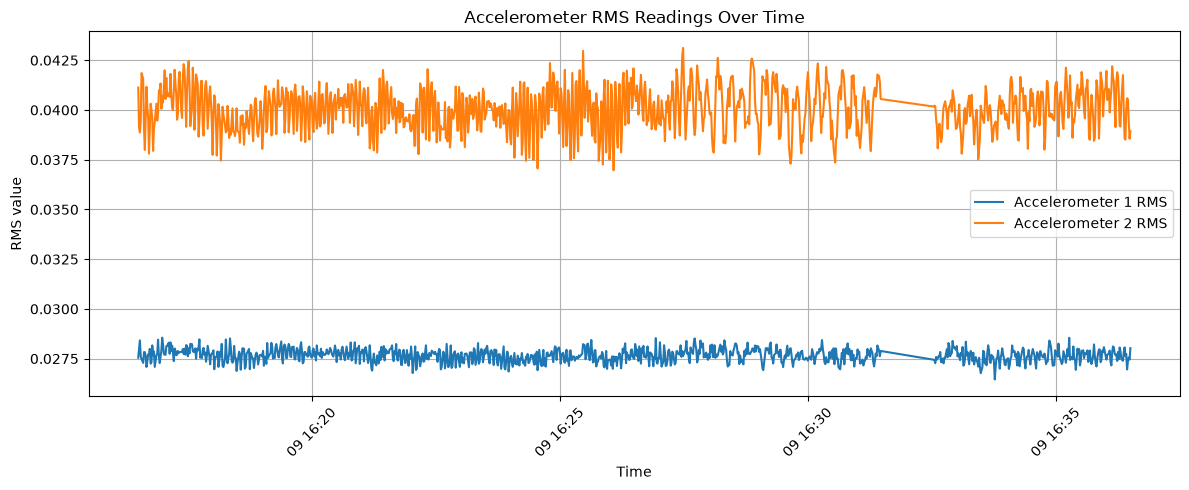

In [5]:

import matplotlib.pyplot as plt

# Plot accelerometer RMS values over time
plt.figure(figsize=(12, 5))

plt.plot(
    df["datetime"],
    df["Accelerometer1RMS"],
    label="Accelerometer 1 RMS"
)

plt.plot(
    df["datetime"],
    df["Accelerometer2RMS"],
    label="Accelerometer 2 RMS"
)

plt.xlabel("Time")
plt.ylabel("RMS value")
plt.title("Accelerometer RMS Readings Over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [6]:

print("Anomaly label counts:")
print(df["anomaly"].value_counts())

print("\nChange-point label counts:")
print(df["changepoint"].value_counts())

print("\nRows with unusually high current:")
print(
    df.loc[
        df["Current"] > 10,
        ["datetime", "Current", "Voltage", "anomaly", "changepoint"]
    ]
)


Anomaly label counts:
anomaly
0.0    730
1.0    333
Name: count, dtype: int64

Change-point label counts:
changepoint
0.0    1059
1.0       4
Name: count, dtype: int64

Rows with unusually high current:
                datetime  Current   Voltage  anomaly  changepoint
1002 2020-03-09 16:35:27  232.734  0.580776      0.0          0.0


In [7]:
print("First 10 anomaly rows:")
print(df[df["anomaly"] == 1].head(10))

print("\nRows around the unusual current reading:")
print(
    df.loc[998:1005, [
        "datetime",
        "Current",
        "Voltage",
        "Accelerometer1RMS",
        "Accelerometer2RMS",
        "anomaly",
        "changepoint"
    ]]
)

First 10 anomaly rows:
               datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
560 2020-03-09 16:26:30           0.027489           0.040797  1.162620   
561 2020-03-09 16:26:31           0.028236           0.040921  0.478813   
562 2020-03-09 16:26:32           0.028028           0.040447  1.212860   
563 2020-03-09 16:26:33           0.027633           0.041229  0.953656   
564 2020-03-09 16:26:34           0.027954           0.040867  1.139300   
565 2020-03-09 16:26:35           0.027384           0.039770  0.449261   
566 2020-03-09 16:26:36           0.028119           0.040324  0.876434   
567 2020-03-09 16:26:38           0.027249           0.041766  0.784459   
568 2020-03-09 16:26:39           0.028023           0.040882  0.450071   
569 2020-03-09 16:26:40           0.027779           0.039835  0.857629   

     Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  \
560 -0.273216      67.4538       24.2726  231.836              32.0000   
561

In [8]:
# Compare sensor readings for normal and anomaly-labelled rows
sensor_columns = [
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "Voltage",
    "Volume Flow RateRMS"
]

comparison = df.groupby("anomaly")[sensor_columns].mean().round(4)

print("Average sensor readings by anomaly label:")
print(comparison)

Average sensor readings by anomaly label:
         Accelerometer1RMS  Accelerometer2RMS  Current  Pressure  Temperature  \
anomaly                                                                         
0.0                 0.0276             0.0400   1.3048    0.0556      67.7797   
1.0                 0.0277             0.0401   0.9551    0.0330      68.1484   

          Voltage  Volume Flow RateRMS  
anomaly                                 
0.0      229.9408              32.1754  
1.0      229.8897              29.9309  


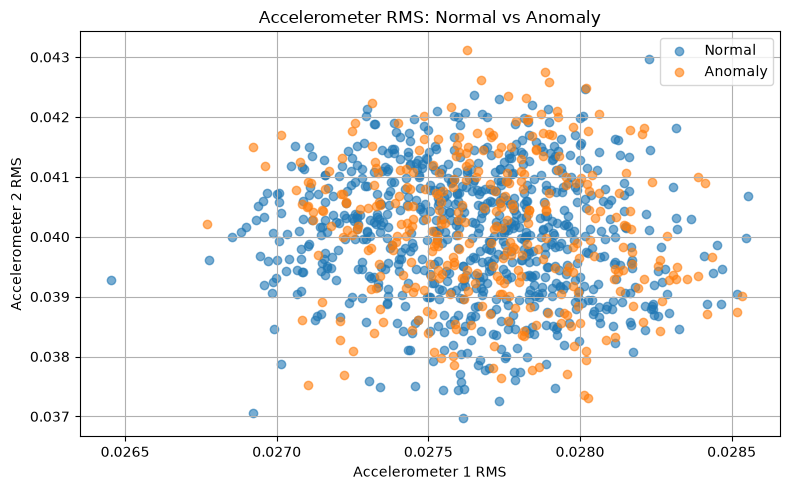

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for label, name in [(0, "Normal"), (1, "Anomaly")]:
    subset = df[df["anomaly"] == label]

    plt.scatter(
        subset["Accelerometer1RMS"],
        subset["Accelerometer2RMS"],
        label=name,
        alpha=0.6
    )

plt.xlabel("Accelerometer 1 RMS")
plt.ylabel("Accelerometer 2 RMS")
plt.title("Accelerometer RMS: Normal vs Anomaly")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
# Check time intervals between consecutive readings
time_diff = df["datetime"].diff().dt.total_seconds()

print("Time interval counts (seconds):")
print(time_diff.value_counts().sort_index())

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst 10 accelerometer readings:")
print(
    df[[
        "datetime",
        "Accelerometer1RMS",
        "Accelerometer2RMS"
    ]].head(10)
)

Time interval counts (seconds):
datetime
1.0     986
2.0      75
64.0      1
Name: count, dtype: int64

Available columns:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 10 accelerometer readings:
             datetime  Accelerometer1RMS  Accelerometer2RMS
0 2020-03-09 16:16:30           0.027545           0.041127
1 2020-03-09 16:16:31           0.027997           0.039100
2 2020-03-09 16:16:32           0.028418           0.038872
3 2020-03-09 16:16:33           0.027625           0.039366
4 2020-03-09 16:16:34           0.027484           0.041854
5 2020-03-09 16:16:36           0.027288           0.041571
6 2020-03-09 16:16:37           0.027832           0.039037
7 2020-03-09 16:16:38           0.027826           0.037990
8 2020-03-09 16:16:39           0.027646           0.039669
9 2020-03-09 16:16:40           0.027084           0.041167


In [11]:
# Find time gaps greater than 2 seconds
time_diff = df["datetime"].diff().dt.total_seconds()

gap_rows = df.loc[
    time_diff > 2,
    ["datetime", "Accelerometer1RMS", "Accelerometer2RMS"]
].copy()

gap_rows["time_gap_seconds"] = time_diff[time_diff > 2]

print("Rows with time gaps greater than 2 seconds:")
print(gap_rows)

Rows with time gaps greater than 2 seconds:
               datetime  Accelerometer1RMS  Accelerometer2RMS  \
838 2020-03-09 16:32:32           0.027447           0.040173   

     time_gap_seconds  
838              64.0  


In [12]:
from pathlib import Path

# Create the output folder if needed
clean_folder = Path("../data/clean")
clean_folder.mkdir(parents=True, exist_ok=True)

# Save a separate copy of the current dataset
output_file = clean_folder / "sensor_data_clean.csv"
df.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("File location:", output_file.resolve())
print("Rows and columns:", df.shape)

Dataset saved successfully!
File location: C:\Users\Sowmya\OneDrive\Desktop\soumya\Sensor-Telemetry-Anomaly-detection-\data\clean\sensor_data_clean.csv
Rows and columns: (1063, 11)


In [ ]:
import pandas as pd
from pathlib import Path

clean_file = Path("../data/clean/sensor_data_clean.csv")

clean_df = pd.read_csv(clean_file)

print("Saved dataset loaded successfully!")
print("Shape:", clean_df.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())
print("\nFirst 5 rows:")
print(clean_df.head())

Saved dataset loaded successfully!
Shape: (1063, 11)

Missing values:
datetime               0
Accelerometer1RMS      0
Accelerometer2RMS      0
Current                0
Pressure               0
Temperature            0
Thermocouple           0
Voltage                0
Volume Flow RateRMS    0
anomaly                0
changepoint            0
dtype: int64

First 5 rows:
              datetime  Accelerometer1RMS  Accelerometer2RMS   Current  \
0  2020-03-09 16:16:30           0.027545           0.041127  0.673506   
1  2020-03-09 16:16:31           0.027997           0.039100  0.772264   
2  2020-03-09 16:16:32           0.028418           0.038872  0.675520   
3  2020-03-09 16:16:33           0.027625           0.039366  0.566279   
4  2020-03-09 16:16:34           0.027484           0.041854  1.292170   

   Pressure  Temperature  Thermocouple  Voltage  Volume Flow RateRMS  anomaly  \
0  0.054711      67.8345       24.3164  240.513                 32.0      0.0   
1  0.054711      67.

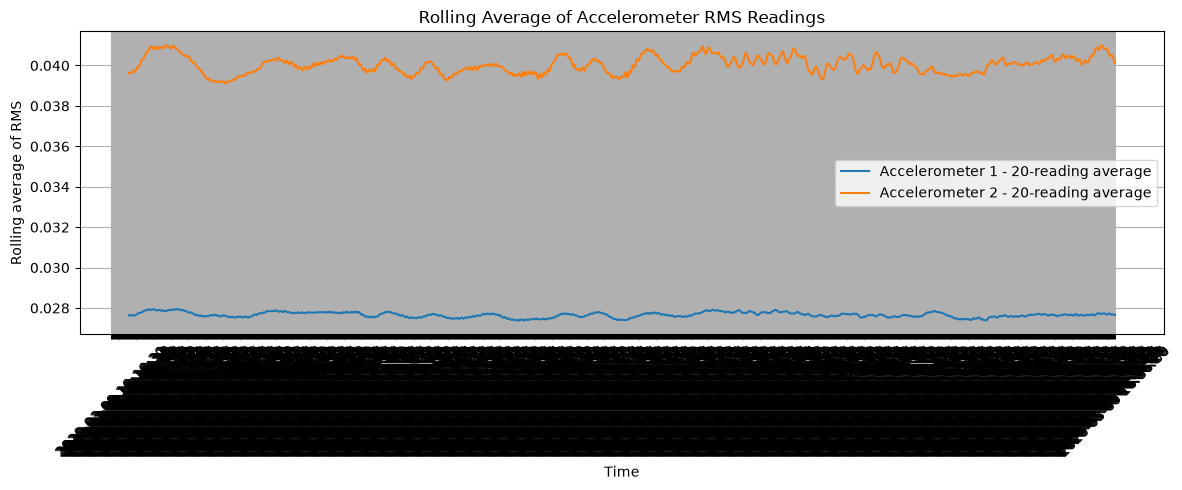

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    clean_df["datetime"],
    clean_df["Accelerometer1RMS"].rolling(window=20).mean(),
    label="Accelerometer 1 - 20-reading average"
)

plt.plot(
    clean_df["datetime"],
    clean_df["Accelerometer2RMS"].rolling(window=20).mean(),
    label="Accelerometer 2 - 20-reading average"
)

plt.xlabel("Time")
plt.ylabel("Rolling average of RMS")
plt.title("Rolling Average of Accelerometer RMS Readings")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    clean_df["datetime"],
    clean_df["Accelerometer1RMS"].rolling(20).mean(),
    label="Accelerometer 1"
)

ax.plot(
    clean_df["datetime"],
    clean_df["Accelerometer2RMS"].rolling(20).mean(),
    label="Accelerometer 2"
)

ax.set_xlabel("Time")
ax.set_ylabel("20-reading rolling average")
ax.set_title("Rolling Average of Accelerometer RMS Readings")

# Display only 6 time labels
positions = np.linspace(0, len(clean_df) - 1, 6, dtype=int)
ax.set_xticks(clean_df["datetime"].iloc[positions])
ax.tick_params(axis="x", rotation=30)

ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

In [1]:

import pandas as pd

# Load the raw sensor dataset
df = pd.read_csv("../data/raw/1.csv", sep=";")

# Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)


Dataset shape: (1063, 11)

Column names:
['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']

First 5 rows:


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
0,2020-03-09 16:16:30,0.027545,0.041127,0.673506,0.054711,67.8345,24.3164,240.513,32.0,0.0,0.0
1,2020-03-09 16:16:31,0.027997,0.039100,0.772264,0.054711,67.8704,24.3279,229.523,32.0,0.0,0.0
2,2020-03-09 16:16:32,0.028418,0.038872,0.675520,0.054711,67.7882,24.3261,242.708,32.0,0.0,0.0
3,2020-03-09 16:16:33,0.027625,0.039366,0.566279,-0.273216,67.7918,24.3323,229.709,32.0,0.0,0.0
4,2020-03-09 16:16:34,0.027484,0.041854,1.292170,0.054711,67.7368,24.3250,242.746,32.0,0.0,0.0



Data types:
datetime                   str
Accelerometer1RMS      float64
Accelerometer2RMS      float64
Current                float64
Pressure               float64
Temperature            float64
Thermocouple           float64
Voltage                float64
Volume Flow RateRMS    float64
anomaly                float64
changepoint            float64
dtype: object


In [2]:

# Summary of accelerometer readings
print("Accelerometer 1 summary:")
display(df["Accelerometer1RMS"].describe())

print("\nAccelerometer 2 summary:")
display(df["Accelerometer2RMS"].describe())

# Check how many anomaly records exist
print("\nAnomaly counts:")
display(df["anomaly"].value_counts())

Accelerometer 1 summary:


count    1063.000000
mean        0.027663
std         0.000333
min         0.026455
25%         0.027434
50%         0.027674
75%         0.027892
max         0.028554
Name: Accelerometer1RMS, dtype: float64


Accelerometer 2 summary:


count    1063.000000
mean        0.040037
std         0.001086
min         0.036972
25%         0.039276
50%         0.040098
75%         0.040828
max         0.043122
Name: Accelerometer2RMS, dtype: float64


Anomaly counts:


anomaly
0.0    730
1.0    333
Name: count, dtype: int64

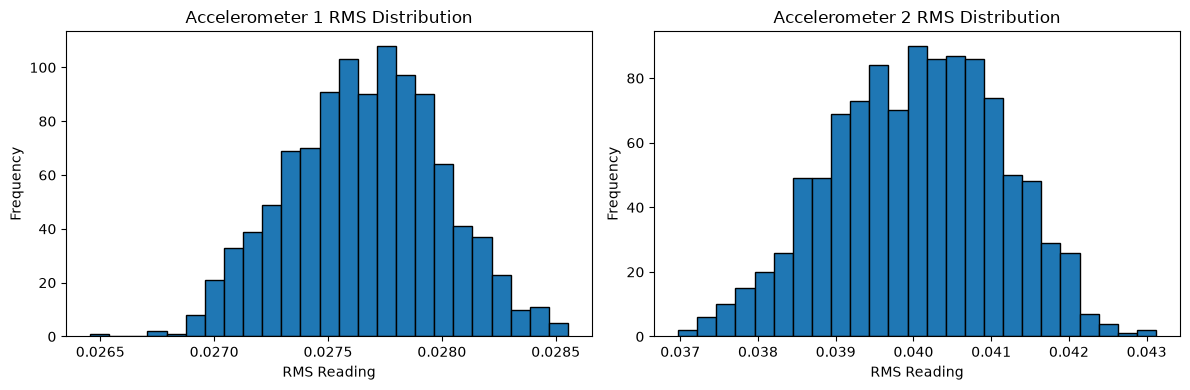

In [3]:

import matplotlib.pyplot as plt

# Create two histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Accelerometer1RMS"], bins=25, edgecolor="black")
axes[0].set_title("Accelerometer 1 RMS Distribution")
axes[0].set_xlabel("RMS Reading")
axes[0].set_ylabel("Frequency")

axes[1].hist(df["Accelerometer2RMS"], bins=25, edgecolor="black")
axes[1].set_title("Accelerometer 2 RMS Distribution")
axes[1].set_xlabel("RMS Reading")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


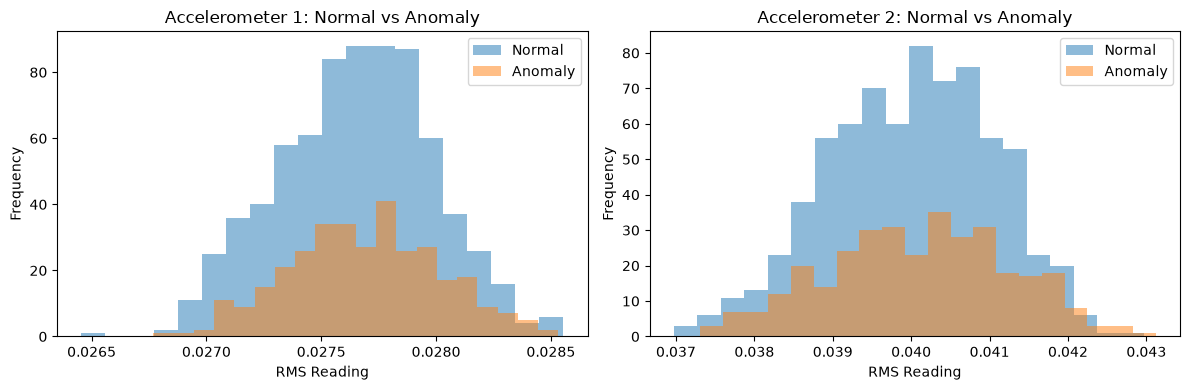

In [4]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, group in df.groupby("anomaly"):
    name = "Anomaly" if label == 1 else "Normal"

    axes[0].hist(
        group["Accelerometer1RMS"],
        bins=20,
        alpha=0.5,
        label=name
    )

    axes[1].hist(
        group["Accelerometer2RMS"],
        bins=20,
        alpha=0.5,
        label=name
    )

axes[0].set_title("Accelerometer 1: Normal vs Anomaly")
axes[0].set_xlabel("RMS Reading")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].set_title("Accelerometer 2: Normal vs Anomaly")
axes[1].set_xlabel("RMS Reading")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()


In [5]:

# Compare sensor readings by anomaly label
comparison = df.groupby("anomaly")[
    ["Accelerometer1RMS", "Accelerometer2RMS"]
].agg(["mean", "min", "max"])

print("RMS comparison: Normal vs Anomaly")
display(comparison)


RMS comparison: Normal vs Anomaly


Accelerometer1RMS                     Accelerometer2RMS            \
                     mean       min       max              mean       min   
anomaly                                                                     
0.0              0.027650  0.026455  0.028554          0.040007  0.036972   
1.0              0.027692  0.026769  0.028533          0.040102  0.037304   

                   
              max  
anomaly            
0.0      0.042974  
1.0      0.043122

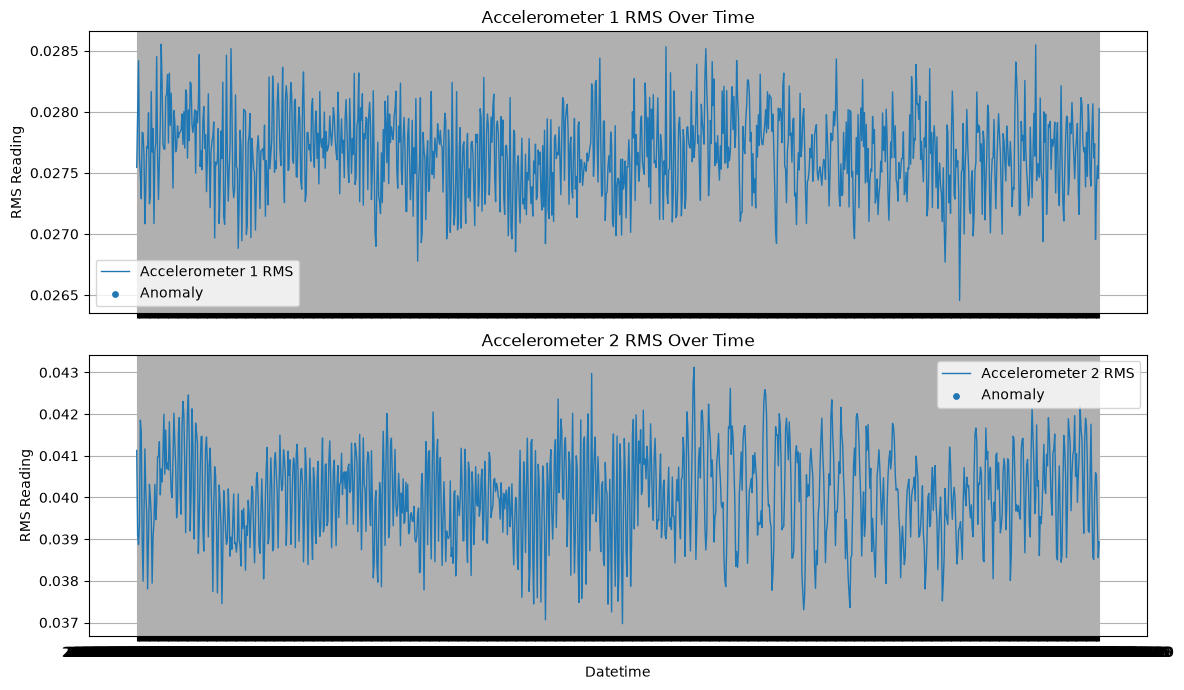

In [6]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Accelerometer 1
axes[0].plot(
    df["datetime"],
    df["Accelerometer1RMS"],
    label="Accelerometer 1 RMS",
    linewidth=1
)

anomalies = df["anomaly"] == 1

axes[0].scatter(
    df.loc[anomalies, "datetime"],
    df.loc[anomalies, "Accelerometer1RMS"],
    label="Anomaly",
    s=15
)

axes[0].set_title("Accelerometer 1 RMS Over Time")
axes[0].set_ylabel("RMS Reading")
axes[0].legend()
axes[0].grid(True)

# Accelerometer 2
axes[1].plot(
    df["datetime"],
    df["Accelerometer2RMS"],
    label="Accelerometer 2 RMS",
    linewidth=1
)

axes[1].scatter(
    df.loc[anomalies, "datetime"],
    df.loc[anomalies, "Accelerometer2RMS"],
    label="Anomaly",
    s=15
)

axes[1].set_title("Accelerometer 2 RMS Over Time")
axes[1].set_xlabel("Datetime")
axes[1].set_ylabel("RMS Reading")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


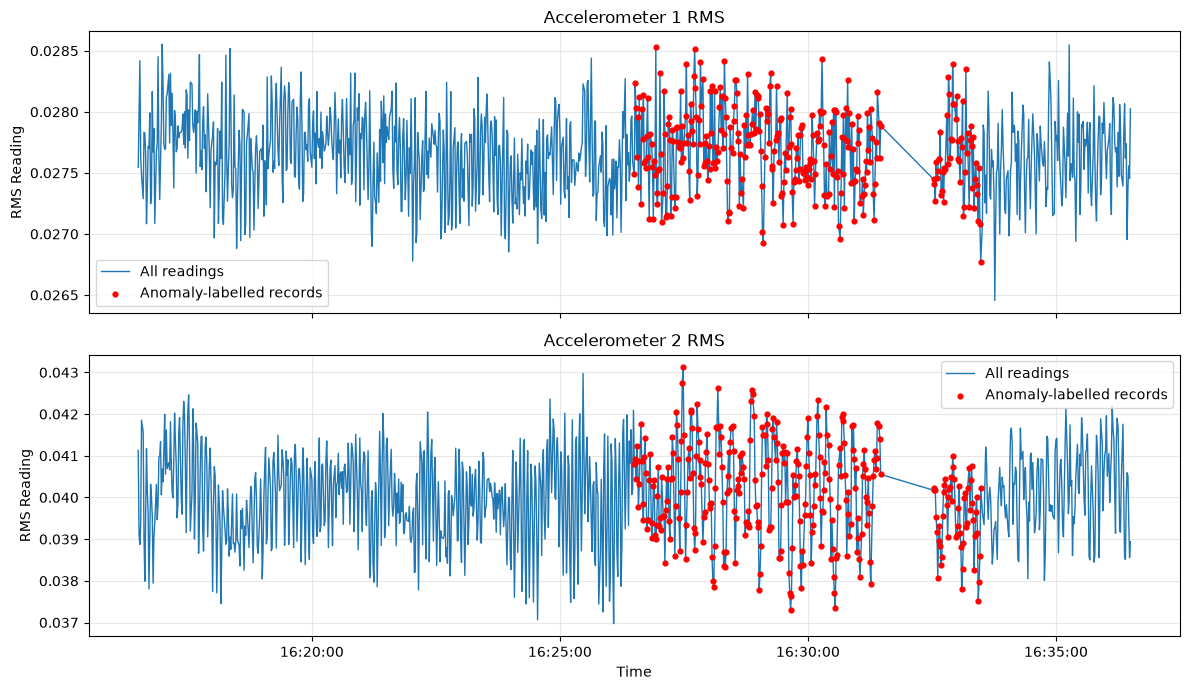

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convert timestamps if not already converted
df["datetime"] = pd.to_datetime(df["datetime"])

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

sensor_columns = [
    ("Accelerometer1RMS", "Accelerometer 1 RMS"),
    ("Accelerometer2RMS", "Accelerometer 2 RMS")
]

anomalies = df["anomaly"] == 1

for ax, (column, title) in zip(axes, sensor_columns):
    ax.plot(
        df["datetime"], df[column],
        linewidth=1, label="All readings"
    )

    ax.scatter(
        df.loc[anomalies, "datetime"],
        df.loc[anomalies, column],
        color="red", s=12,
        label="Anomaly-labelled records",
        zorder=3
    )

    ax.set_title(title)
    ax.set_ylabel("RMS Reading")
    ax.legend()
    ax.grid(True, alpha=0.3)

# Display a manageable number of date labels
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=6))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

